> **Versão histórica com rótulos artificiais.** O treino observado SPHEREx + Gaia substitui esta versão em `08_spherex_gaia_observados.ipynb`. O comando `sprints` agora usa dados observados por padrão.

# Sprints 2 e 3 — ranking inteligente e objetos móveis

O protótipo agora transforma os candidatos do SPHEREx em uma lista de revisão,
procura trajetórias entre exposições e gera animações e empilhamentos.

**Como usar:** veja primeiro o ranking e as animações abaixo. Pontuação alta
significa prioridade para olhar, não certeza de ser asteroide.

O XGBoost foi treinado com fontes e artefatos artificiais sobre os fundos reais.
Os candidatos reais não têm rótulo confirmado; suas classes são previsões.
O treinamento possui limite automático de **dois minutos**.

In [17]:
import json
from pathlib import Path

import numpy as np
from astropy.table import Table
from IPython.display import JSON, Image, display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
OUT = ROOT / "outputs/sprints"
s2 = json.loads((OUT / "sprint2_report.json").read_text())
s3 = json.loads((OUT / "sprint3_report.json").read_text())
ranking = json.loads((OUT / "candidate_ranking.json").read_text())
tracks = json.loads((OUT / "tracks.json").read_text())
print(
    f"Treinamento: {s2['training']['status']} "
    f"em {s2['training'].get('wall_seconds', 0):.2f} segundo(s)"
)
print(f"{len(ranking)} candidatos ordenados • {len(tracks)} trajetórias propostas")
print(f"Empilhamentos de trajetórias reais: {s3['n_real_track_stacks']}")

Treinamento: complete em 0.81 segundo(s)
206 candidatos ordenados • 13 trajetórias propostas
Empilhamentos de trajetórias reais: 5


## Ranking para revisão

O classificador olha o formato do ponto, seu brilho em relação ao ruído, se ele
parece o formato esperado de uma fonte e se está perto de pixels mascarados.
A prioridade final combina o modelo com a presença em várias épocas.

`Parece fonte` e `parece artefato` são as classes do protótipo. A pontuação de
0 a 100 serve para ordenar o trabalho de revisão. Os números não são
probabilidades de um candidato ser um asteroide.

ordem,id,prioridade_0_a_100,classe_prevista,epocas_da_trajetoria,perto_fonte_catalogada
int64,int64,float64,str12,int64,bool
1,29,73.7,parece fonte,4,True
2,64,71.5,parece fonte,5,True
3,96,71.4,parece fonte,4,True
4,200,70.4,parece fonte,6,True
5,91,70.0,parece fonte,5,True
6,24,69.7,parece fonte,5,True
7,164,69.6,parece fonte,4,True
8,111,68.8,parece fonte,4,False
9,45,68.7,parece fonte,5,True


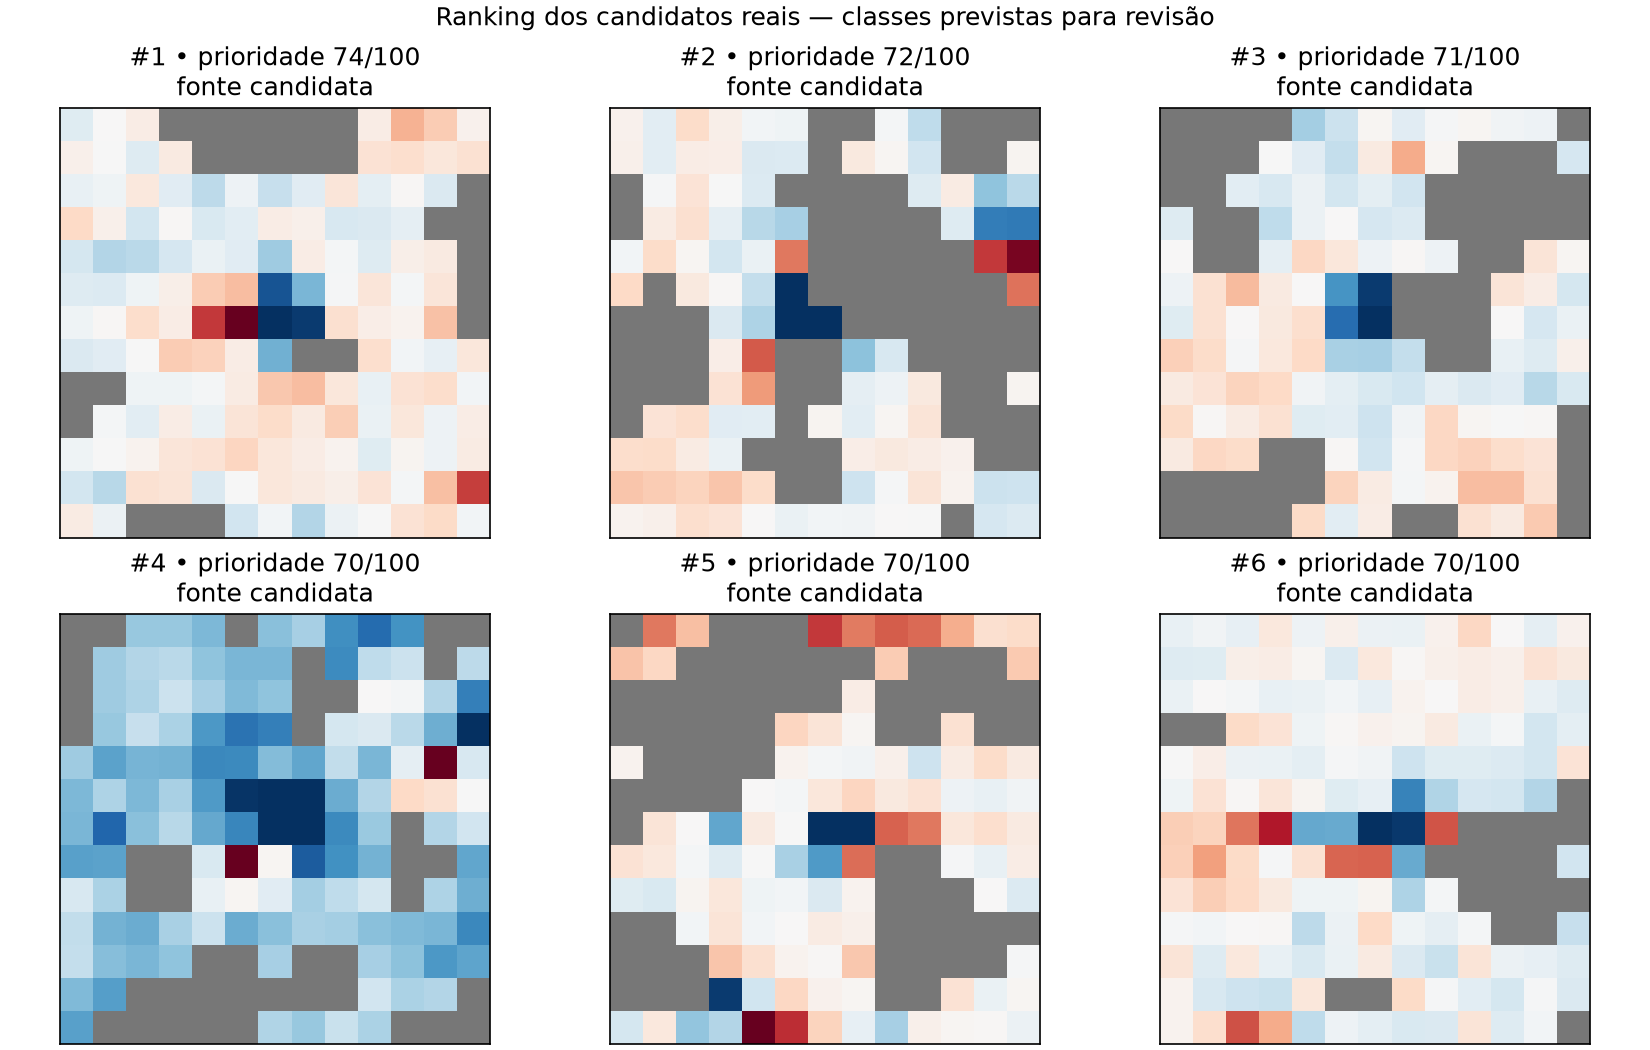

In [18]:
rows = []
for c in ranking[:15]:
    rows.append(
        {
            "ordem": c["rank"],
            "id": c["candidate_id"],
            "prioridade_0_a_100": round(c["priority_score"], 1),
            "classe_prevista": "parece fonte"
            if c["predicted_class"] == "fonte_candidata"
            else "parece artefato",
            "epocas_da_trajetoria": c["motion_support_epochs"],
            "perto_fonte_catalogada": c["overlaps_reference_source"],
        }
    )
display(Table(rows=rows))
display(Image(filename=str(OUT / "ranking.png")))

O arquivo `candidate_ranking.csv` contém a lista completa. `review_labels.csv`
está pronto para revisão humana: preencha `human_label` e `notes` sem alterar
os IDs. Esses rótulos poderão alimentar uma próxima versão do classificador.

## Trajetórias e movimento

**Cross-matching de posição:** compara as coordenadas do candidato com as fontes
SEP da primeira exposição. Uma coincidência de posição é uma pista, não uma
identificação. Não foi feita associação com órbitas ou catálogo de asteroides.

**Tracklet:** uma sequência curta de pelo menos três posições em épocas distintas.
**Velocity matching:** verifica se dois tracklets podem seguir a mesma velocidade.
Também há uma ligação direta de posições no intervalo completo, com pelo menos
quatro épocas e velocidade ajustada em conjunto.

Resíduos negativos pertencem à época da referência, e positivos à imagem nova.
Repetições do mesmo ponto na mesma época são fundidas para não criar movimento
artificial contando uma exposição várias vezes.

Posições perto de fontes da referência: 76
Eventos após fundir repetições na mesma época: 194
Tracklets em cada grupo temporal: [0, 6]
Ligações entre tracklets que passaram pelo teste de velocidade: 0
Trajetórias propostas no conjunto completo: 13


trajetoria,epocas,vx_pixel_por_hora,vy_pixel_por_hora,erro_medio_pixel,metodo
int64,int64,float64,float64,float64,str55
1,7,-4.5,9.22,0.49,position seeds across temporal groups + fitted velocity
2,6,11.52,2.49,0.42,position seeds across temporal groups + fitted velocity
3,6,-3.89,-1.84,0.66,position seeds across temporal groups + fitted velocity
4,5,-6.02,1.23,0.26,position seeds across temporal groups + fitted velocity
5,5,-7.23,-7.45,0.41,position seeds across temporal groups + fitted velocity
6,5,-1.77,0.0,0.42,position seeds across temporal groups + fitted velocity
7,5,3.7,1.96,0.48,position seeds across temporal groups + fitted velocity
8,5,1.03,10.59,0.51,position seeds across temporal groups + fitted velocity
9,4,-4.39,3.58,0.33,position seeds across temporal groups + fitted velocity


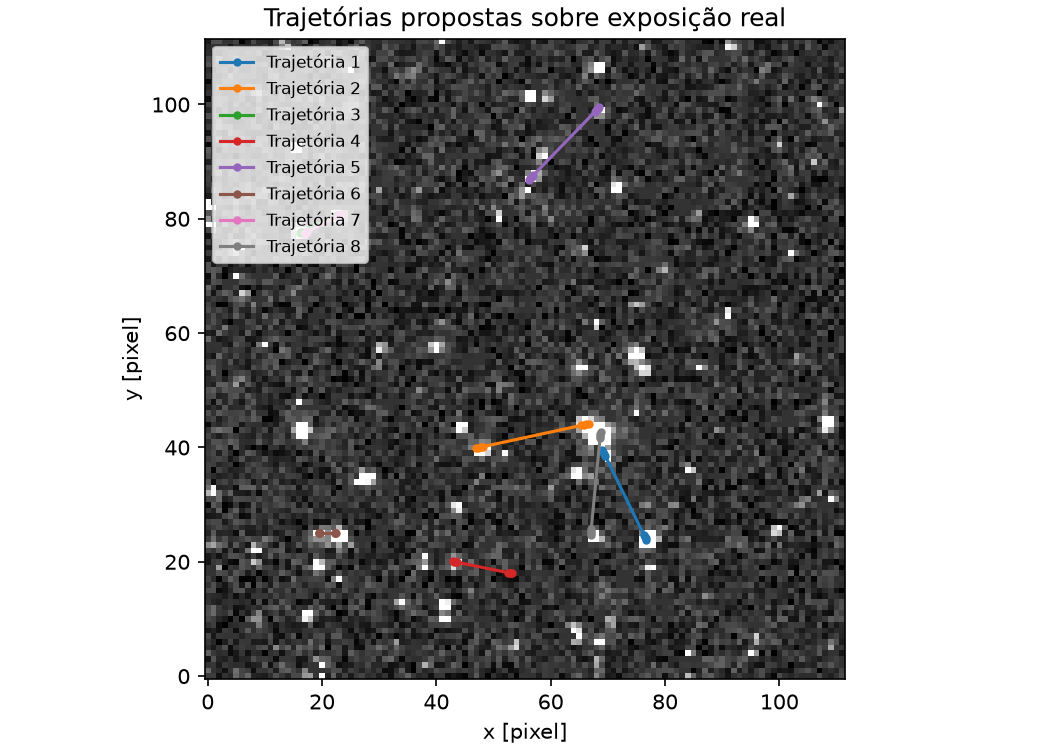

In [19]:
print("Posições perto de fontes da referência:", s3["n_positional_matches"])
print("Eventos após fundir repetições na mesma época:", s3["n_unique_epoch_events"])
print("Tracklets em cada grupo temporal:", s3["n_tracklets_per_group"])
print(
    "Ligações entre tracklets que passaram pelo teste de velocidade:",
    s3["n_velocity_matched_tracks"],
)
print("Trajetórias propostas no conjunto completo:", s3["n_combined_tracks"])
if tracks:
    display(
        Table(
            rows=[
                {
                    "trajetoria": t["track_id"],
                    "epocas": t["n_epochs"],
                    "vx_pixel_por_hora": round(t["vx"], 2),
                    "vy_pixel_por_hora": round(t["vy"], 2),
                    "erro_medio_pixel": round(t["rms_pixels"], 2),
                    "metodo": t["link_method"],
                }
                for t in tracks[:10]
            ]
        )
    )
display(Image(filename=str(OUT / "tracks.png")))

## Animação de um candidato real

O círculo acompanha uma trajetória proposta sobre as exposições reais.
A animação ajuda a revisar se existe uma fonte consistente no caminho. A linha
ajustada sozinha não estabelece a natureza do objeto.

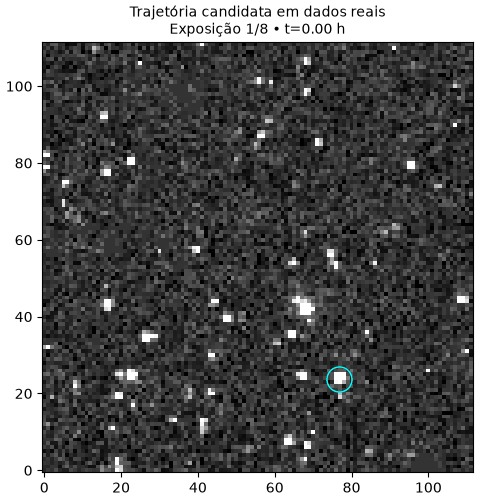

In [20]:
candidate_gif = OUT / "candidate_blink.gif"
if candidate_gif.exists():
    display(Image(filename=str(candidate_gif)))
else:
    print("Nenhuma trajetória real disponível para animação nesta execução.")

## Shift-and-Stack

Há dois grupos de quatro exposições em cerca de 1h43min, com um intervalo de
aproximadamente 90 minutos entre grupos. O protótipo tenta empilhar as imagens
acompanhando até cinco trajetórias que tenham deslocamento mensurável no recorte.
A aproximação de movimento linear é usada para esta demonstração.

Na figura, a coluna esquerda soma sem acompanhar o movimento; a direita segue
a trajetória. O círculo indica a posição na época de referência. A linha de
controle acrescenta explicitamente uma fonte artificial sobre o fundo real.

Empilhamento habilitado: True
Janela: 1.71 h • maior intervalo: 89.7 min


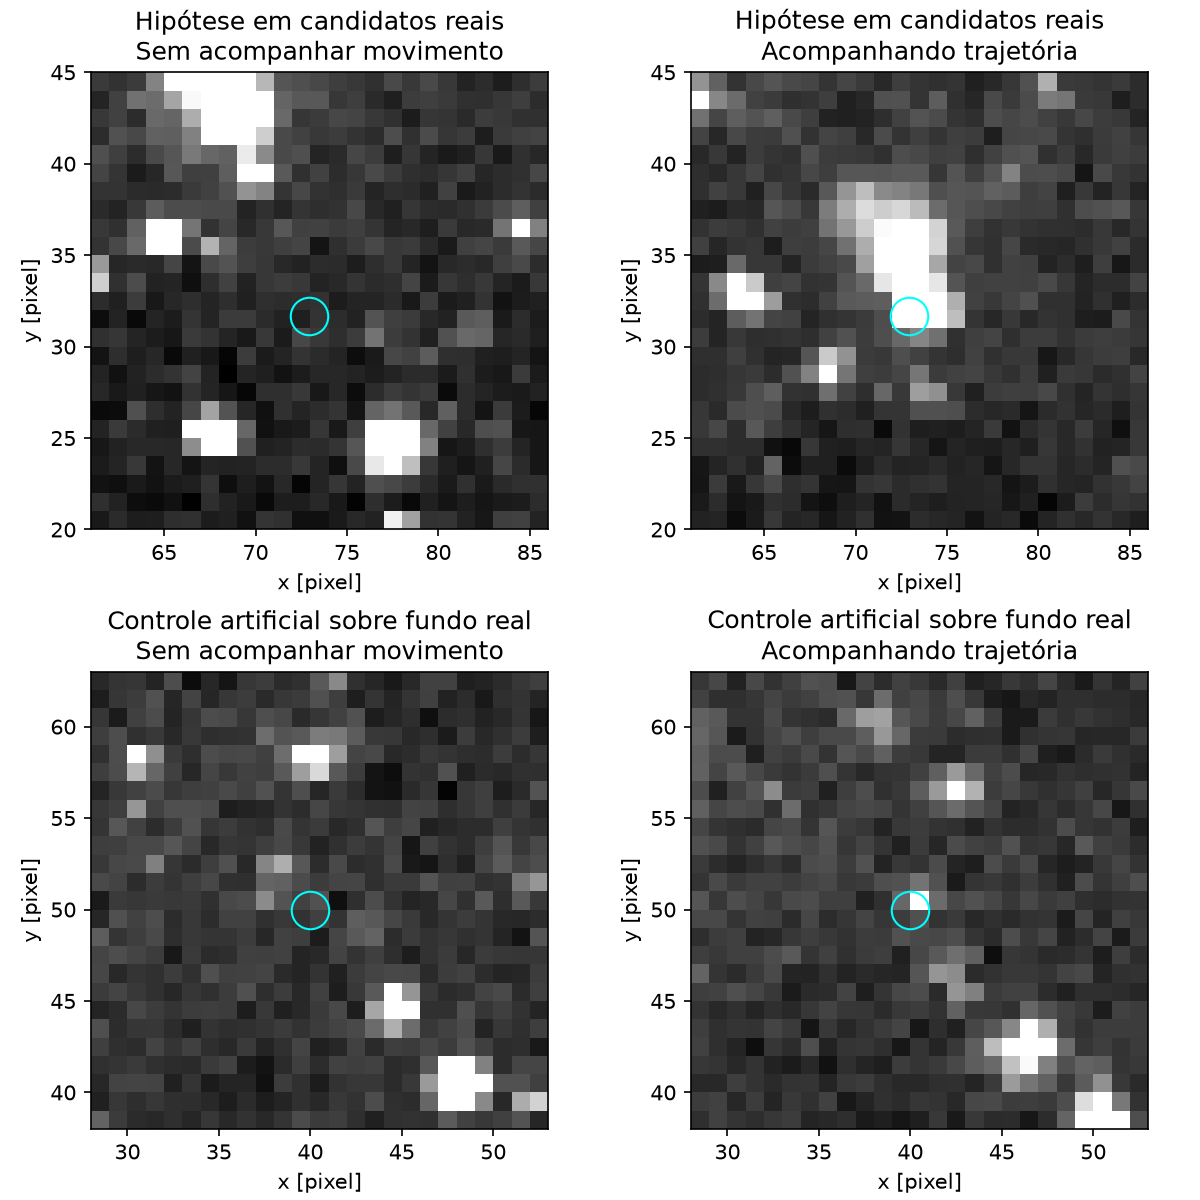

In [21]:
cadence = s3["cadence"]
print("Empilhamento habilitado:", cadence["eligible"])
print(
    f"Janela: {cadence['span_hours']:.2f} h • "
    f"maior intervalo: {cadence['largest_gap_minutes']:.1f} min"
)
display(Image(filename=str(OUT / "stack_comparison.png")))

## Controle visual separado

A animação abaixo contém uma **fonte artificial** em movimento sobre as imagens
reais. Serve para demonstrar o acompanhamento e o empilhamento de uma trajetória
conhecida. Não é uma descoberta do protótipo.

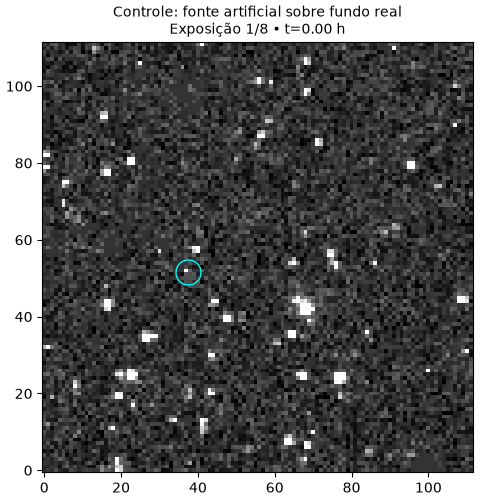

Controle de ligação de posições com movimento conhecido recuperado: True


In [22]:
display(Image(filename=str(OUT / "control_blink.gif")))
print(
    "Controle de ligação de posições com movimento conhecido recuperado:",
    s3["linking_control"]["recovered"],
)

## O treinamento, em termos simples

Foram gerados 900 exemplos conhecidos: fontes artificiais e artefatos como pixels
quentes, rastros, dipolos e pontos que imitam fontes. O XGBoost aprende diferenças
entre esses formatos. Regiões separadas do céu são usadas para treino, ajuste da
parada e avaliação; coordenadas e tipos injetados não entram como características.

O modelo atual tem desempenho modesto no conjunto reservado. Ele entrega um
ranking experimental, com revisão manual, sem decidir sozinho se um evento é real.
Esses números se referem aos controles artificiais, não à identificação dos
candidatos reais do SPHEREx.

In [23]:
metrics = s2["training"]
if metrics["status"] == "complete":
    matrix = np.array(metrics["confusion_matrix"])
    print(
        f"Acertos nos controles reservados: {np.trace(matrix)}/{matrix.sum()} "
        f"({np.trace(matrix) / matrix.sum():.0%})"
    )
    print("Exemplos de treino:", metrics["n_train"])
    print("Exemplos usados para parada antecipada:", metrics["n_validation"])
    print("Exemplos reservados para avaliação:", metrics["n_test"])
    print(
        f"Tempo total do treino: {metrics['wall_seconds']:.2f} s; "
        f"limite {metrics['budget_seconds']:.0f} s"
    )
else:
    print("Treino não concluído; ranking heurístico identificado no relatório:", metrics["status"])

Acertos nos controles reservados: 98/170 (58%)
Exemplos de treino: 570
Exemplos usados para parada antecipada: 160
Exemplos reservados para avaliação: 170
Tempo total do treino: 0.81 s; limite 120 s


## Executar novamente

```bash
uv run --extra ml spherex-tracking sprints
```

Para reutilizar o treinamento e refazer somente ranking e movimento:

```bash
uv run --extra ml spherex-tracking sprints --reuse-training
```

O limite padrão do treino é 120 segundos. O processo é encerrado se ultrapassar
esse tempo; a execução registra o fato e usa um ranking heurístico identificado.
Os artefatos estão em `outputs/sprints/`. A implementação usa XGBoost em CPU,
com duas threads e parada antecipada.

In [24]:
display(JSON({"sprint2": s2, "sprint3": s3}))

<IPython.core.display.JSON object>